# 14 · Evaluation: every model, one test set, honest error bars

**Objective.** Answer the brief's question with one set of tables: *does graph learning beat independent-segment models on METR-LA, at which horizons, and at which times of day?*

**Rules of the comparison** (all fixed before looking at test numbers):

* the same 6,901 test windows (the last 24 days) for every model, history window 12 steps for every model
* a target counts only if it was observed **and** every model produced a finite forecast for it (common mask)
* forecasts clipped to 0–70 mph; MAE, RMSE and MAPE at 5 / 15 / 30 / 60 minutes
* peak = weekdays 07–10 and 15–19 at the **target** time
* uncertainty from a **day-block bootstrap**: whole test days are resampled, because errors within a day are strongly correlated
* deep-learning rows are the seed-42 run unless they say "mean of 3 seeds"

This notebook writes `reports/dl_results_summary.md`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}")

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import preprocessing as pp, visualization as viz, evaluation as ev
from deep_learning.dl import results

viz.apply_style()
ctx = pp.load_context()
SEEDS = (42, 1, 2)
main = list(results.MODELS)
seed_runs = [f"dl_{m}_s{s}" for m in ("gru", "st_gat_noedge", "st_gat") for s in (1, 2)]
keys = main + seed_runs
preds, y, ymask, origins, horizons, missing = ev.load_aligned(keys, "test", ctx.speed, ctx.mask)
assert not missing, missing
valid = ev.common_valid_mask(preds, ymask)
print(f"{len(origins):,} test windows x {len(horizons)} horizons x 207 sensors; "
      f"{valid.mean():.1%} of target cells are scored (the rest were sensor outages)")

6,901 test windows x 4 horizons x 207 sensors; 88.0% of target cells are scored (the rest were sensor outages)


## 1 · Leaderboard by horizon

In [3]:
t = ev.metrics_by_horizon(preds, y, valid, horizons)
def wide(metric, ks=main):
    w = t.pivot(index="model", columns="horizon_min", values=metric).loc[ks]
    w.index = [results.label(k) for k in ks]
    w.columns = [f"{c} min" for c in w.columns]
    return w
for metric in ("MAE", "RMSE", "MAPE"):
    print(metric + (" (%)" if metric == "MAPE" else " (mph)"))
    display(wide(metric).round(3 if metric != "MAPE" else 2))

MAE (mph)


,5 min,15 min,30 min,60 min
Persistence,2.816,3.492,4.189,5.347
Seasonal average,4.176,4.176,4.176,4.177
XGBoost,2.310,2.835,3.262,3.685
XGBoost + neighbours,2.230,2.759,3.182,3.651
GRU (time only),2.318,2.825,3.217,3.626
"ST-GAT, edges removed",2.309,2.811,3.192,3.567
ST-GAT,2.216,2.669,3.043,3.459
DCRNN,2.206,2.666,3.045,3.494


RMSE (mph)


,5 min,15 min,30 min,60 min
Persistence,4.613,6.376,7.985,10.245
Seasonal average,7.829,7.829,7.829,7.829
XGBoost,4.080,5.591,6.639,7.530
XGBoost + neighbours,3.854,5.306,6.361,7.386
GRU (time only),4.076,5.533,6.514,7.436
"ST-GAT, edges removed",4.071,5.562,6.643,7.563
ST-GAT,3.805,5.084,6.124,7.194
DCRNN,3.776,5.102,6.182,7.338


MAPE (%)


,5 min,15 min,30 min,60 min
Persistence,6.47,8.57,10.79,14.42
Seasonal average,12.97,12.97,12.97,12.97
XGBoost,5.64,7.62,9.51,11.54
XGBoost + neighbours,5.33,7.31,9.14,11.32
GRU (time only),5.63,7.52,9.25,11.07
"ST-GAT, edges removed",5.61,7.49,9.16,10.75
ST-GAT,5.28,6.85,8.38,10.12
DCRNN,5.21,6.84,8.37,10.25


In [4]:
fam = t.pivot(index="model", columns="horizon_min", values="MAE")
seed_table = pd.DataFrame({
    results.label(f"dl_{m}_s42"): fam.loc[[f"dl_{m}_s{s}" for s in SEEDS]].agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)
    for m in ("gru", "st_gat_noedge", "st_gat")}).T
seed_table.columns = [f"{c} min" for c in seed_table.columns]
print("Test MAE, mean ± std over seeds 42 / 1 / 2")
display(seed_table)

Test MAE, mean ± std over seeds 42 / 1 / 2


,5 min,15 min,30 min,60 min
GRU (time only),2.316 ± 0.002,2.824 ± 0.001,3.216 ± 0.002,3.610 ± 0.014
"ST-GAT, edges removed",2.311 ± 0.002,2.817 ± 0.009,3.201 ± 0.012,3.577 ± 0.010
ST-GAT,2.223 ± 0.010,2.676 ± 0.010,3.053 ± 0.013,3.470 ± 0.012


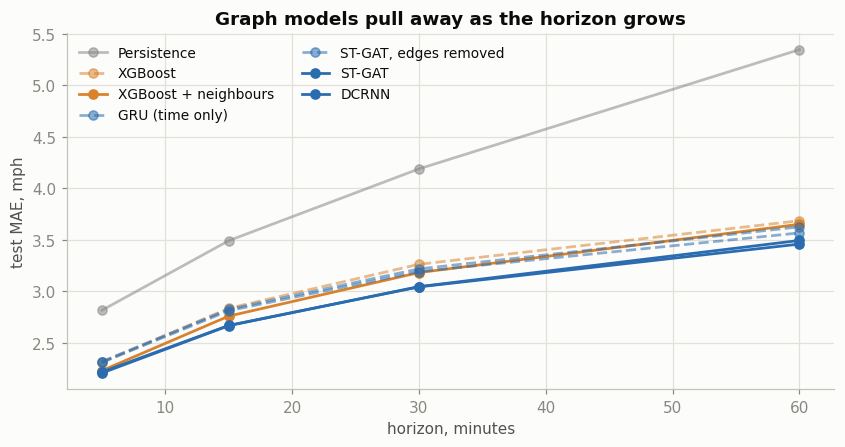

In [5]:
colours = {"baseline": "#888888", "Phase 1 ML": "#d9822b", "deep learning": "#2b6cb0"}
fig, ax = plt.subplots(figsize=(9, 4.2))
for k in main:
    lab, family = results.MODELS[k]
    if k == "seasonal_avg":
        continue
    r = t[t.model == k]
    ls = "--" if k in ("xgboost", "dl_gru_s42", "dl_st_gat_noedge_s42") else "-"
    ax.plot(r.horizon_min, r.MAE, ls, marker="o", c=colours[family], alpha=1 if k in ("dl_st_gat_s42", "dl_dcrnn_s42", "xgboost_spatial") else .55, label=lab)
ax.set(xlabel="horizon, minutes", ylabel="test MAE, mph", title="Graph models pull away as the horizon grows")
ax.legend(fontsize=9, ncol=2); plt.show()

## 2 · Peak vs off-peak

Rush hour is where forecasting matters and where it is hardest: speeds change fastest.

In [6]:
peak = ev.peak_flags_sh(ctx.timestamps, origins, horizons)
g = ev.metrics_by_group({k: preds[k] for k in main}, y, valid, horizons, {"peak": peak, "off-peak": ~peak})
pk = g.pivot_table(index="model", columns=["group", "horizon_min"], values="MAE").loc[main]
pk.index = [results.label(k) for k in main]
display(pk.round(3))
print(f"share of scored test targets in peak: {(valid & peak[:, :, None]).sum() / valid.sum():.1%}")

group                 off-peak                        peak                \
horizon_min                 5      15     30     60     5      15     30   
Persistence              2.664  3.158  3.693  4.619  3.314  4.587  5.818   
Seasonal average         3.464  3.464  3.464  3.465  6.517  6.517  6.517   
XGBoost                  2.118  2.482  2.771  3.052  2.940  3.998  4.877   
XGBoost + neighbours     2.068  2.434  2.725  3.032  2.763  3.829  4.683   
GRU (time only)          2.125  2.477  2.751  3.029  2.952  3.968  4.750   
ST-GAT, edges removed    2.117  2.466  2.735  2.994  2.942  3.944  4.692   
ST-GAT                   2.057  2.371  2.634  2.931  2.737  3.645  4.388   
DCRNN                    2.051  2.376  2.637  2.944  2.717  3.622  4.386   

group                         
horizon_min               60  
Persistence            7.740  
Seasonal average       6.517  
XGBoost                5.766  
XGBoost + neighbours   5.684  
GRU (time only)        5.588  
ST-GAT, edges removed  5.451  
ST-GAT                 5.194  
DCRNN                  5.301

share of scored test targets in peak: 23.3%


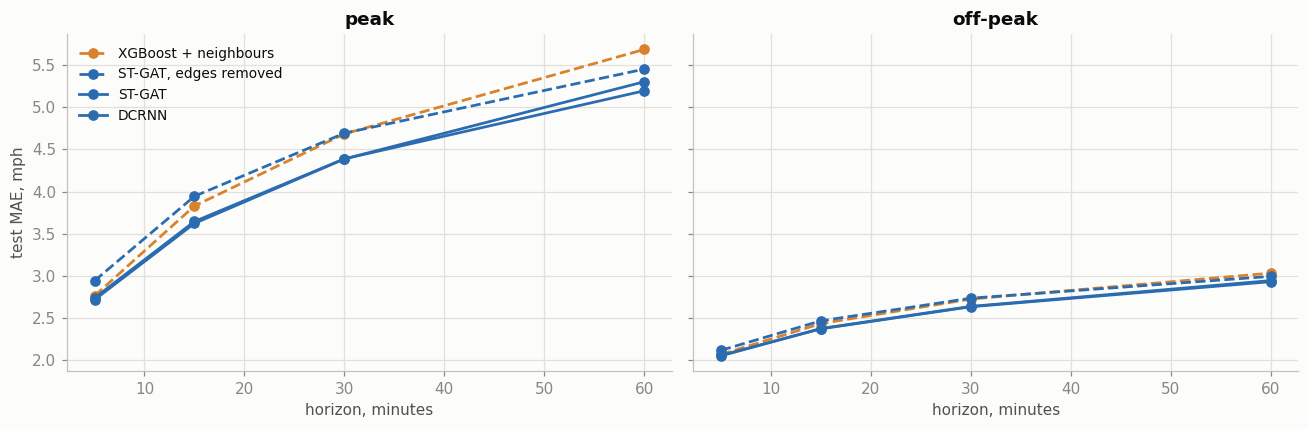

In [7]:
sel = ["xgboost_spatial", "dl_st_gat_noedge_s42", "dl_st_gat_s42", "dl_dcrnn_s42"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, grp in zip(axes, ("peak", "off-peak")):
    for k in sel:
        r = g[(g.group == grp) & (g.model == k)]
        ax.plot(r.horizon_min, r.MAE, marker="o", c=colours[results.MODELS[k][1]], ls="--" if "noedge" in k or k == "xgboost_spatial" else "-",
                label=results.label(k))
    ax.set(title=grp, xlabel="horizon, minutes")
axes[0].set_ylabel("test MAE, mph"); axes[0].legend(fontsize=9); plt.tight_layout(); plt.show()

## 3 · Are the gains real? Day-block bootstrap

For each comparison and horizon: percent reduction in MAE, with a 95 % interval from 2,000 resamples of the 24 test days. "share > 0" is the fraction of resamples in which the newer model wins.

In [8]:
tt = ev.target_timestamps(ctx.timestamps, origins, horizons)
day = pd.to_datetime(tt.ravel()).normalize()
day = pd.factorize(day)[0].reshape(tt.shape)
pairs = [("xgboost_spatial", "dl_st_gat_s42"), ("xgboost_spatial", "dl_dcrnn_s42"),
         ("dl_st_gat_noedge_s42", "dl_st_gat_s42"), ("dl_gru_s42", "dl_st_gat_noedge_s42"), ("dl_dcrnn_s42", "dl_st_gat_s42")]
rows = []
for ref, new in pairs:
    for j, h in enumerate(horizons):
        r = ev.day_block_bootstrap_improvement(preds[ref][:, j], preds[new][:, j], y[:, j], valid[:, j], day[:, j])
        rows.append({"comparison": f"{results.label(new)} vs {results.label(ref)}", "horizon": f"{h * 5} min",
                     "MAE reduction %": r["improvement_pct"], "95% CI": f"[{r['ci_low']:.1f}, {r['ci_high']:.1f}]",
                     "share > 0": r["share_boot_positive"]})
boot = pd.DataFrame(rows)
display(boot.pivot(index="comparison", columns="horizon", values="MAE reduction %").round(1)[["5 min", "15 min", "30 min", "60 min"]])
display(boot.set_index(["comparison", "horizon"]).round(3))

horizon,5 min,15 min,30 min,60 min
comparison,,,,
DCRNN vs XGBoost + neighbours,1.0,3.4,4.3,4.3
ST-GAT vs DCRNN,-0.4,-0.1,0.1,1.0
"ST-GAT vs ST-GAT, edges removed",4.1,5.1,4.7,3.0
ST-GAT vs XGBoost + neighbours,0.6,3.3,4.4,5.3
"ST-GAT, edges removed vs GRU (time only)",0.4,0.5,0.8,1.6


MAE reduction %  \
comparison                               horizon                    
ST-GAT vs XGBoost + neighbours           5 min              0.625   
                                         15 min             3.283   
                                         30 min             4.368   
                                         60 min             5.265   
DCRNN vs XGBoost + neighbours            5 min              1.048   
                                         15 min             3.361   
                                         30 min             4.288   
                                         60 min             4.304   
ST-GAT vs ST-GAT, edges removed          5 min              4.053   
                                         15 min             5.069   
                                         30 min             4.662   
                                         60 min             3.039   
ST-GAT, edges removed vs GRU (time only) 5 min              0.365   
                                         15 min             0.492   
                                         30 min             0.802   
                                         60 min             1.628   
ST-GAT vs DCRNN                          5 min             -0.428   
                                         15 min            -0.081   
                                         30 min             0.084   
                                         60 min             1.005   

                                                        95% CI  share > 0  
comparison                               horizon                           
ST-GAT vs XGBoost + neighbours           5 min      [0.5, 0.8]      1.000  
                                         15 min     [2.9, 3.7]      1.000  
                                         30 min     [3.6, 5.1]      1.000  
                                         60 min     [4.3, 6.2]      1.000  
DCRNN vs XGBoost + neighbours            5 min      [0.9, 1.2]      1.000  
                                         15 min     [2.9, 3.9]      1.000  
                                         30 min     [3.4, 5.1]      1.000  
                                         60 min     [3.3, 5.3]      1.000  
ST-GAT vs ST-GAT, edges removed          5 min      [3.7, 4.4]      1.000  
                                         15 min     [4.6, 5.6]      1.000  
                                         30 min     [4.1, 5.3]      1.000  
                                         60 min     [2.4, 3.6]      1.000  
ST-GAT, edges removed vs GRU (time only) 5 min      [0.3, 0.4]      1.000  
                                         15 min     [0.2, 0.7]      1.000  
                                         30 min     [0.3, 1.2]      0.998  
                                         60 min     [1.0, 2.2]      1.000  
ST-GAT vs DCRNN                          5 min    [-0.6, -0.2]      0.000  
                                         15 min    [-0.4, 0.2]      0.274  
                                         30 min    [-0.5, 0.7]      0.608  
                                         60 min     [0.0, 1.9]      0.976

## 4 · Against the literature

Published METR-LA numbers (MAE at 15 / 30 / 60 min) from the original papers, as collected in the Graph WaveNet paper (Wu et al., 2019). **They are not directly comparable**: those papers use a 70 / 10 / 20 split of *windows* (test = last 20 % ≈ 24 days, close to ours), exclude zeros only in the target, and report the average of a different set of days. Use the table as a sanity check on order of magnitude, not as a ranking.

In [9]:
lit = pd.DataFrame([
    ("Historical average", 4.16, 4.16, 4.16), ("ARIMA (Kalman)", 3.99, 5.15, 6.90), ("FC-LSTM", 3.44, 3.77, 4.37),
    ("STGCN", 2.88, 3.47, 4.59), ("DCRNN (Li et al. 2018)", 2.77, 3.15, 3.60), ("Graph WaveNet", 2.69, 3.07, 3.53),
    ("GMAN", 2.80, 3.12, 3.44)], columns=["model", "15 min", "30 min", "60 min"]).set_index("model")
ours = wide("MAE").loc[[results.label(k) for k in ("seasonal_avg", "xgboost_spatial", "dl_st_gat_s42", "dl_dcrnn_s42")], ["15 min", "30 min", "60 min"]]
ours.index = [f"ours: {i}" for i in ours.index]
display(pd.concat([lit, ours.round(2)]))

,15 min,30 min,60 min
Historical average,4.16,4.16,4.16
ARIMA (Kalman),3.99,5.15,6.90
FC-LSTM,3.44,3.77,4.37
STGCN,2.88,3.47,4.59
DCRNN (Li et al. 2018),2.77,3.15,3.60
Graph WaveNet,2.69,3.07,3.53
GMAN,2.80,3.12,3.44
ours: Seasonal average,4.18,4.18,4.18
ours: XGBoost + neighbours,2.76,3.18,3.65
ours: ST-GAT,2.67,3.04,3.46


**Sanity checks that pass:** our seasonal average (4.18) matches the published historical average (4.16), and our DCRNN is about 0.1 mph *lower* than the paper's at every horizon. That gap most likely comes from the different test days and mask, not from a better implementation; we do not claim to beat the published DCRNN.

## 5 · Write the summary report

In [10]:
def md(df):
    # DataFrame -> markdown table without the optional tabulate dependency
    if df.index.nlevels == 1 and df.index.name is None:
        df = df.rename_axis("model")
    df = df.reset_index()
    cols = [" ".join(map(str, c)).strip() if isinstance(c, tuple) else str(c) for c in df.columns]
    rows = [" | ".join(map(str, r)) for r in df.itertuples(index=False)]
    return "\n".join(["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)] + ["| " + r + " |" for r in rows])

g60 = boot[(boot.horizon == "60 min")].set_index("comparison")
best60 = wide("MAE")["60 min"].idxmin()
lines = [
    "# Deep-learning phase: results summary", "",
    "_Generated by `deep_learning/notebooks/14_dl_evaluation.ipynb`. Do not edit by hand._", "",
    f"Test period: last 24 days ({len(origins):,} forecast windows), common mask ({valid.mean():.1%} of target cells scored), "
    "predictions clipped to 0-70 mph. DL rows are seed 42 unless marked.", "",
    "## Test MAE (mph) by horizon", "", md(wide("MAE").round(3)), "",
    "## Test RMSE (mph) by horizon", "", md(wide("RMSE").round(3)), "",
    "## Test MAPE (%) by horizon", "", md(wide("MAPE").round(2)), "",
    "## Seed stability (test MAE, mean ± std over seeds 42/1/2)", "", md(seed_table), "",
    "## Peak vs off-peak (test MAE, mph)", "", md(pk.round(3)), "",
    "## Day-block bootstrap: MAE reduction (%) with 95% CI", "",
    md(boot.set_index(["comparison", "horizon"])[["MAE reduction %", "95% CI", "share > 0"]].round(2)), "",
    "## Key findings", "",
    f"- Best model at 60 minutes: **{best60}**.",
    f"- Removing the graph edges from ST-GAT (same parameters, same training) raises 60-minute MAE by "
    f"{wide('MAE').loc['ST-GAT, edges removed', '60 min'] - wide('MAE').loc['ST-GAT', '60 min']:.3f} mph.",
    f"- ST-GAT vs XGBoost + neighbours at 60 min: {g60.loc['ST-GAT vs XGBoost + neighbours', 'MAE reduction %']:.1f}% lower MAE, "
    f"95% CI {g60.loc['ST-GAT vs XGBoost + neighbours', '95% CI']}.",
    "- A time-only GRU roughly ties XGBoost: the network alone is not the win, the graph is.",
    "- Note: Phase 1 XGBoost was re-run for this comparison and scores 0.01-0.05 mph worse than the committed Phase 1 numbers "
    "(cause not traced); the re-runs are used so every model is scored on identical points.",
]
out = config.PROJECT_ROOT / "reports" / "dl_results_summary.md"
out.write_text("\n".join(lines) + "\n")
print("wrote", out.relative_to(config.PROJECT_ROOT))

wrote reports/dl_results_summary.md


## Common mistakes

* **Different masks per model.** If one model skips the hard points (outage edges), it wins for free. The common mask prevents that.
* **Point-level bootstrap.** Resampling single forecasts treats 2 million correlated errors as independent and gives intervals far too narrow.
* **Comparing to the literature as if it were a leaderboard.** Splits, masks and test days differ.
* **Reporting only the best seed.** Seed spread here is ~0.01 mph; any claim smaller than that is noise.

## Check yourself

1. Why is the peak MAE almost twice the off-peak MAE for every model?
2. A bootstrap interval for "ST-GAT vs DCRNN" crosses zero at some horizons. What may you claim?
3. Why do we bootstrap over *days* and not over *sensors*?